In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../')

import oasis_dla

In [2]:
circuit = qiskit.QuantumCircuit(1)
circuit.h(0)
circuit.ry(0, 0)

gen = oasis_dla.extract_generators(circuit)

display(gen)

# dla = oasis_dla.construct_dla(gen)

# print(f"Computed DLA: \n{dla}")
# print(f"dim(g): {len(dla)}")

[array([[-1.+0.j,  1.+0.j],
        [ 1.+0.j,  1.+0.j]]),
 array([[0.+0.j, 0.-1.j],
        [0.+1.j, 0.+0.j]])]

In [3]:
# print(f"Var(cost) ~ 1/dim(g) = {1/len(dla)}")

In [4]:
vqls = oasis_dla.VQLS(qubits=1)

A = np.array([
    [1, 1],
    [0, 5]
])

b = np.array([
    [1],
    [-1]
])

X = np.array([
    [0, 1],
    [1, 0]
])

Y = np.array([
    [0, -1j],
    [1j, 0]
])

Z = np.array([
    [1, 0],
    [0, -1]
])

# pauli_matrices = [np.eye(2), X, Y, Z]
# coeffs = [0.5 * np.trace(P @ A) for P in pauli_matrices]

# sum = np.zeros((2, 2), np.complex128)
# for i, p in enumerate(pauli_matrices):
#     sum += (coeffs[i] * p)
# sum

solution = vqls.solve(A, b, shots=10_000)

print(solution.solution())
solution.get_probabilities()
print(np.linalg.solve(A, b))


local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.886579864025407e-15
       x: [ 4.382e+00]
     nit: 38
   maxcv: 0.0
    nfev: 22
[[ 1.2+0.j]
 [-0.2+0.j]]
[[ 1.2]
 [-0.2]]


local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.9984014443252818e-15
       x: [ 4.382e+00]
     nit: 42
   maxcv: 0.0
    nfev: 25
[{'0': 0.9757, '1': 0.0243}]
classical probabilities: [0.97297297 0.02702703]


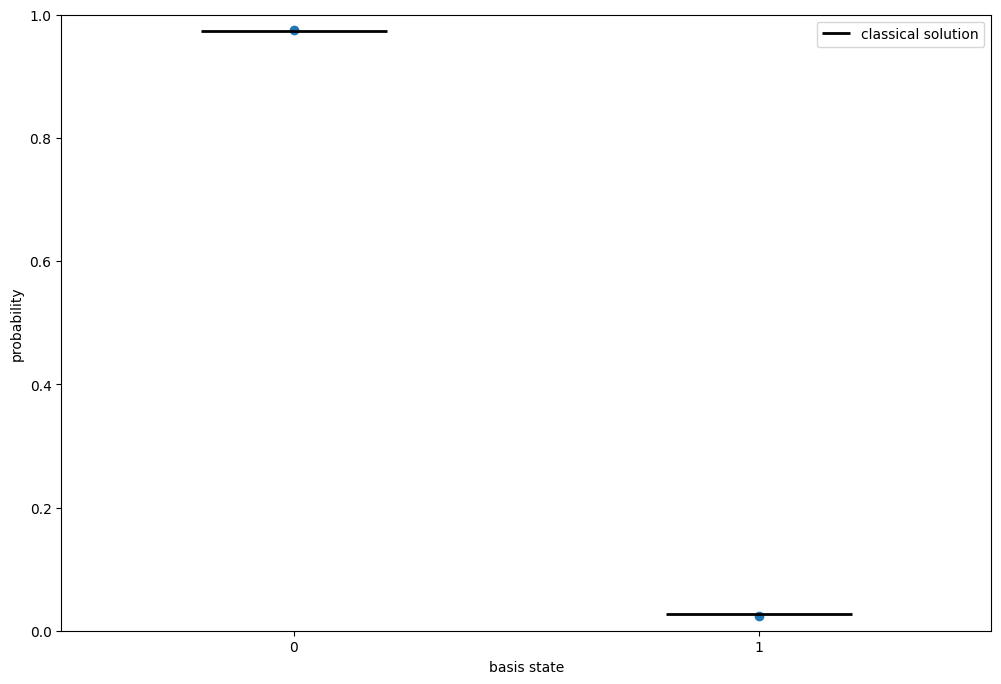

In [5]:
prob_list = []
for i in range(0, 1):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))
# short horizontal line centered on each basis state at its classical probability
ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.887379141862766e-15
       x: [ 4.382e+00]
     nit: 43
   maxcv: 0.0
    nfev: 21
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 3.608224830031759e-15
       x: [ 4.382e+00]
     nit: 36
   maxcv: 0.0
    nfev: 23
[{'0': 0.9745, '1': 0.0255}, {'0': 0.9712, '1': 0.0288}]
classical probabilities: [0.97297297 0.02702703]


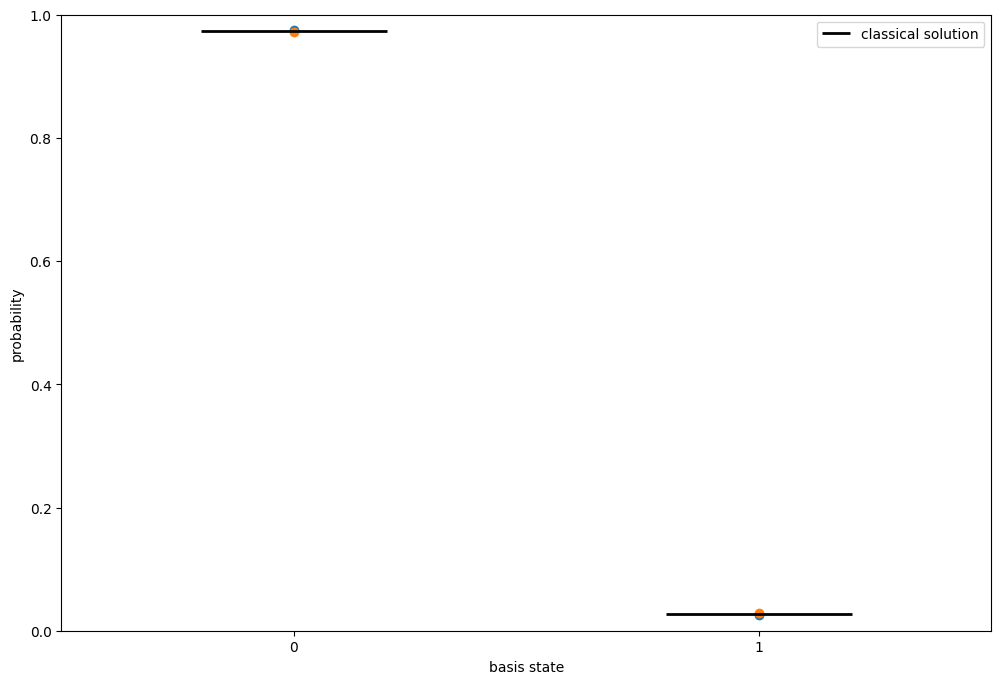

In [6]:
prob_list = []
for i in range(0, 2):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))

ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

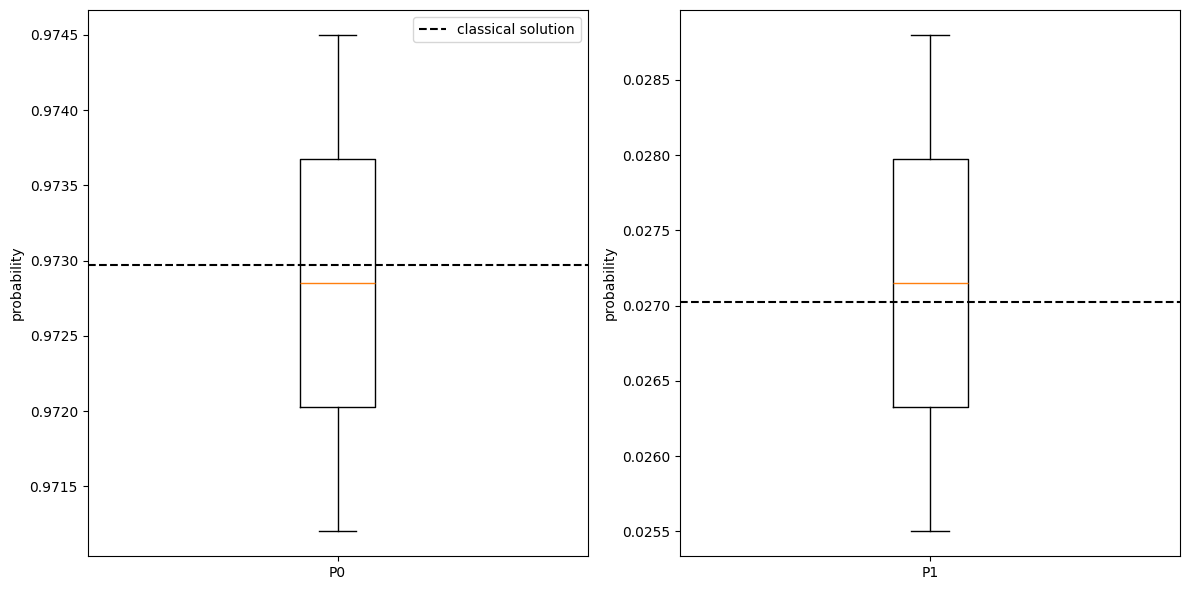

In [7]:
P0s = [probs.get("0", 0) for probs in prob_list]
P1s = [probs.get("1", 0) for probs in prob_list]

# separate panel
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, data, p_true, label in zip(axes, [P0s, P1s], p_classical, ["P0", "P1"]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
plt.tight_layout()
plt.show()

# testing 1 qubit vqls on a suite of real and then complex matrices

In [8]:
random_c = lambda: random.random() + 1j * random.random()
random_r = random.random

A = np.array([
    [1, random_c()],
    [1, 1]
])
b = 1/np.sqrt(2) * np.array([
    [1],
    [1]
])
print(A)
qres = vqls.solve(A, b).solution()#.reshape(-1, 1)
cres = np.linalg.solve(A,b)
print(f"Quantum Solution: \n{qres}\n")
print(f"Classical Solution: \n{cres}\n")

# project qres onto cres
np.linalg.norm(qres - cres)

[[1.        +0.j         0.19879018+0.46146859j]
 [1.        +0.j         1.        +0.j        ]]
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.220446049250313e-16
       x: [-1.571e+00]
     nit: 41
   maxcv: 0.0
    nfev: 22
Quantum Solution: 
[[7.07106781e-01-1.96668490e-10j]
 [8.52359154e-10-2.37067713e-19j]]

Classical Solution: 
[[0.70710678+0.j]
 [0.        +0.j]]



np.float64(1.0130219252944768e-09)

In [9]:
def res_diff(x, y):
    return 1 - np.linalg.norm(x-y)

def test_vqls(b=None, shots=1):
    Ai = [ # random data set of matrices
        np.array([
            [1, random_c()],
            [random_c(), random_c()]
        ]) for _ in range(shots)
    ]

    if b is None:
        b = 1/np.sqrt(2) * np.array([
            [1],
            [1]
        ])

    accuracies = []
    for A in Ai:
        # print(b)
        q_soln = vqls.solve(A, b).solution()
        c_soln = np.linalg.solve(A, b)
        # print(f"Quantum Solution: \n{q_soln}\n")
        # print(f"Classical Solution: \n{c_soln}\n")

        diff = res_diff(q_soln, c_soln)
        # print(f"Accuracy: {diff}")
        accuracies.append(diff)

    # print(accuracies)

    return accuracies

accuracies = test_vqls()
avg_diff = sum(accuracies) / len(accuracies)

print(f"Average Quantum Solution Accuracy: {avg_diff*100:.2f}%")

local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
local cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.0039884749290363675
       x: [ 6.852e-01]
     nit: 37
   maxcv: 0.0
    nfev: 20
Average Quantum Solution Accuracy: 80.78%


In [10]:
avg_diff, accuracies

(np.float64(0.8077982142246392), [np.float64(0.8077982142246392)])

In [11]:
# plt.plot(np.linspace(0, len(accuracies), 1), accuracies)
# plt.axhline(avg_diff, color='black', linestyle='--', label="Average")
# plt.ylabel("Accuracy")
# plt.xlabel("Test # (random matrix)")
# plt.title("Constant Top Right Entry")
# plt.legend()

[array([[0.6721663 +0.85341744j, 0.37085831+0.43104316j],
       [0.09856985+0.74949517j, 0.42301914+0.84077329j]]), array([[0.41388823+0.64574411j, 0.36300527+0.24079258j],
       [0.82535946+0.13789094j, 0.76240399+0.74404262j]]), array([[0.38855475+0.83445659j, 0.28908787+0.32841856j],
       [0.22569457+0.22034667j, 0.26246057+0.96081168j]])]
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.03033397435419949
       x: [ 4.247e-01]
     nit: 40
   maxcv: 0.0
    nfev: 16
0.5325336559729652
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
 message: The lower bound for the trust-regio

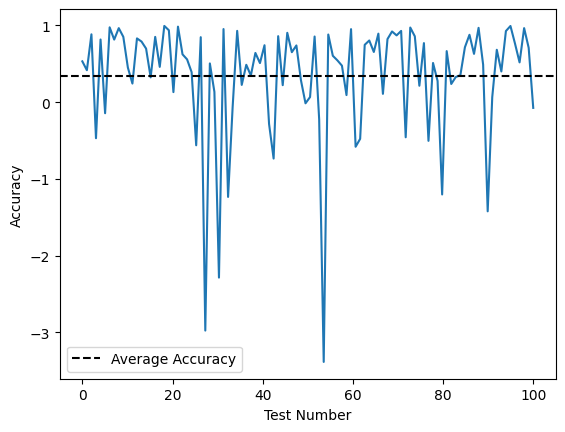

In [25]:
vqls_ry = oasis_dla.VQLS(qubits=1, ansatz_type=0, cost='direct')
vqls_rz = oasis_dla.VQLS(qubits=1, ansatz_type=1, cost='direct')

data = vqls.generate_dataset(random_entries=[1+1j, 2+1j, 3+1j, 4+1j], shots=100)
print(data[:3])

# 1 param ansatz ry h
accuracies = vqls_ry.accuracy_test(data)
vqls_ry.plot_tests(accuracies)

direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.0
       x: [ 3.379e-01 -1.265e+00]
     nit: 43
   maxcv: 0.0
    nfev: 39
0.9999999894723196
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
dir

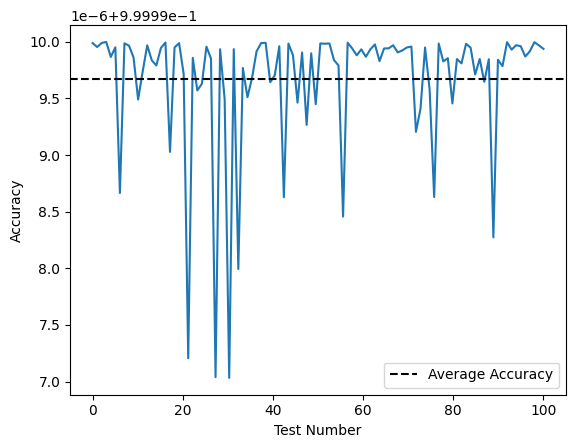

In [26]:
# 2 param ansatz rz ry h
accuracies = vqls_rz.accuracy_test(data)
vqls_rz.plot_tests(accuracies)

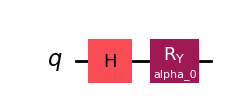

In [27]:
vqls_ry.ansatz.draw('mpl')

In [22]:

def linear_indep(*mats: np.ndarray) -> bool:
    vecs = [m.flatten() for m in mats]
    M = np.column_stack(vecs)
    rank = np.linalg.matrix_rank(M)
    return rank == len(mats)

generators = oasis_dla.extract_generators(vqls_ry.ansatz)
# print(generators)
dla_ry = oasis_dla.construct_dla(generators)
dla_ry

print(f"Generators: \n{generators}")
print(f"DLA: \n{dla_ry}")
print(f"dim g_ry = {len(dla_ry)}")

# other_dla = oasis_dla.fast_numerical_construct_dla(generators)
# print(f"other method dla: {other_dla}")
# print(f"other method dim g = {len(other_dla)}")

# len(other_dla) == len(dla_ry)

Generators: 
[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]]), array([[0.+0.j, 0.-1.j],
       [0.+1.j, 0.+0.j]])]
DLA: 
[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]]), array([[0.+0.j, 0.-1.j],
       [0.+1.j, 0.+0.j]]), array([[0.+2.j, 0.+2.j],
       [0.+2.j, 0.-2.j]])]
dim g_ry = 3


In [23]:
generators = oasis_dla.extract_generators(vqls_rz.ansatz)
generators
dla_rz = oasis_dla.fast_numerical_construct_dla(generators)
print(f"fast closure algorithm: DLA_rz = {dla_rz}")
print(f"dim g_rz = {len(dla_rz)}")

# other_dla_rz = oasis_dla.construct_dla(generators)
# print(f"og algorithm DLA = {other_dla_rz}")
# print(f"dim g = {len(other_dla_rz)}")

# len(other_dla_rz) == len(dla_rz)
# linear_indep(*dla_rz)

fast closure algorithm: DLA_rz = [array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]]), array([[0.+0.j, 0.-1.j],
       [0.+1.j, 0.+0.j]]), array([[ 1.+0.j,  0.+0.j],
       [ 0.+0.j, -1.+0.j]])]
dim g_rz = 3


Closure test:

for two different dla's that I got, the one using the fast numerical generation paper and the one from the diagnosing BP paper, I'll compute closure to check which ones right

In [24]:
# fast numerical lie closure

dla = oasis_dla.fast_numerical_construct_dla(generators)
dla

vecs = [m.flatten() for m in dla]
mat = np.column_stack(vecs)
basis_rank = np.linalg.matrix_rank(mat)
print(f"Rank of basis vector matrix: {basis_rank}")

closure = dla.copy()
for g1 in dla:
    for g2 in dla:
        closure.append(oasis_dla.commutator(g1, g2))


vecs = [m.flatten() for m in closure]
new_mat = np.column_stack(vecs)
new_rank = np.linalg.matrix_rank(new_mat)
print(f"Rank of new vector matrix: {new_rank}")

Rank of basis vector matrix: 3
Rank of new vector matrix: 3


Now that we know we have the right DLA (which is all of su(2) itself), lets compute two things
- $P_\mathfrak{g}(\rho)$
- $Ann_\mathfrak{g}(|b\rangle)$

where $\rho = |b\rangle \langle b|$

In [ ]:
# g-purity first

# hilbert-schmidt inner product
def inner_product(A, B):
    return np.trace(A.conj().T @ B)

# ρ = O in the case of VQLS since the state being measured against |ψ> is |b>
b = (np.ones(2) / np.sqrt(2)).reshape(-1, 1)
rho = b @ b.T.conj()
print(f"ρ = \n{rho}")

# complexify the DLA first
i_dla_ry = []
for g in dla_ry:
    i_dla_ry.append(g + 1j *g)

print(f"g + ig = \n{i_dla_ry}")

# compute g-purity
def g_purity(g, H):
    gpurity = 0
    for B in g:
        gpurity += (inner_product(B, H))**2
    return gpurity

g_purity(i_dla_ry, rho)



ρ = 
[[0.5 0.5]
 [0.5 0.5]]
g + ig = 
[array([[-1.-1.j,  1.+1.j],
       [ 1.+1.j,  1.+1.j]]), array([[ 0.+0.j,  1.-1.j],
       [-1.+1.j,  0.+0.j]]), array([[-2.+2.j, -2.+2.j],
       [-2.+2.j,  2.-2.j]])]
